# Variational Autoencoders

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.dpi'] = 150

In [2]:
# Check available hardware
import torch
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print(f'Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

GPU is available, using GPU Tesla T4


## Dataset: MNIST

In [3]:
import torch
import torchvision
from torchvision.transforms import v2

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])
mnist = torchvision.datasets.MNIST(root='~/scr10/', train=True, transform=transform, download=True)
mnist_test = torchvision.datasets.MNIST(root='~/scr10/', train=False, transform=transform, download=False)
from torch.utils.data import random_split
mnist_train, mnist_val = random_split(mnist, [0.8, 0.2])
print('Training dataset has length', len(mnist_train))
print('Training dataset has length', len(mnist_val))
print('Training dataset has length', len(mnist_test))

Training dataset has length 48000
Training dataset has length 12000
Training dataset has length 10000


In [4]:
x, y = mnist_train[0]
print('Input has shape', x.shape, 'and the output is', y)

Input has shape torch.Size([1, 28, 28]) and the output is 9


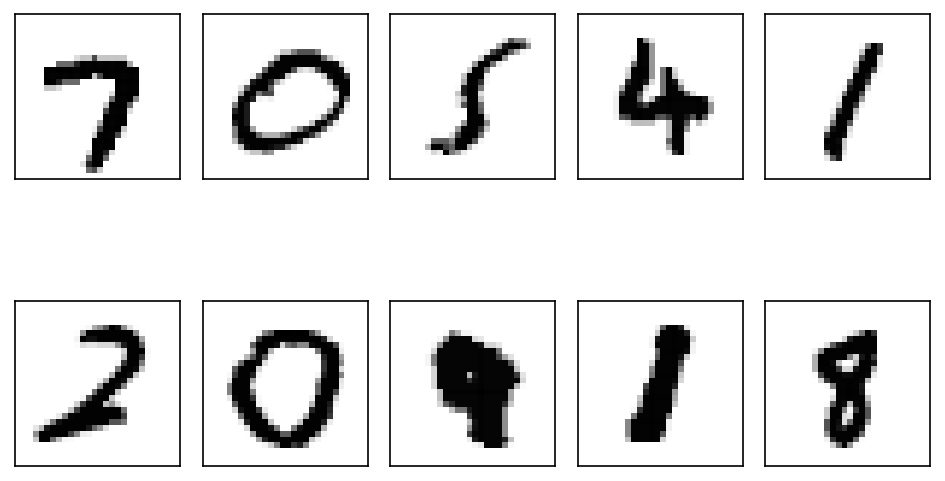

In [5]:
fig, ax = plt.subplots(2, 5, sharex=True, sharey=True)
ax = ax.flatten()
for ii in range(10):
    x, y = mnist_train[np.random.choice(len(mnist_train))]
    ax[ii].imshow(x.squeeze(), cmap='Greys')
    ax[ii].set(xticks=[], yticks=[])
plt.tight_layout()

## Variational autoencoder

In [7]:
import torch.nn as nn
import torch.nn.functional as F

class Encoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.fc = nn.Linear(64*3*3, 4 * 2)

    def forward(self, x):
        # [B, 1, 28, 28]
        x = self.conv1(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)

        # [B, 16, 14, 14]
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)

        # [B, 32, 7, 7]
        x = self.conv3(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)

        # [B, 64, 3, 3]
        x = x.reshape([-1, 64*3*3])
        x = self.fc(x)

        # [B, 4 * 2]
        mu = x[..., :4]
        logvar = x[..., 4:]
        return mu, logvar

class Decoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.ConvTranspose2d(16, 1, kernel_size=3, padding=1)
        self.conv2 = nn.ConvTranspose2d(32, 16, kernel_size=3, padding=1)
        self.conv3 = nn.ConvTranspose2d(64, 32, kernel_size=3, padding=1)

        self.fc = nn.Linear(4, 64*3*3)

    def forward(self, x):
        # [B, 10]
        x = self.fc(x)

        # [B, 64*3*3]
        x = x.reshape([-1, 64, 3, 3])

        x = F.interpolate(x, size=(7, 7))
        x = self.conv3(x)
        x = F.relu(x)

        x = F.interpolate(x, size=(14, 14))
        x = self.conv2(x)
        x = F.relu(x)

        x = F.interpolate(x, size=(28, 28))
        x = self.conv1(x)
        x = F.relu(x)

        return x

class VariationalAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.decoder = Decoder()

    def forward(self, x):
        mu, logvar = self.encoder(x)

        # Sample from N(mu, sigma)
        if self.training:
            noise = torch.randn_like(mu) * (0.5 * logvar).exp()
        else:
            noise = 0.
        z = mu + noise

        x = self.decoder(z)
        return x, z, (mu, logvar)

model = VariationalAutoencoder()
print(x.shape)
xp, zp, params = model(x[None])
print('X reconstructed:', xp.shape)
print('Z latent:', zp.shape)
print(params[0].shape, params[1].shape)

torch.Size([1, 28, 28])
X reconstructed: torch.Size([1, 1, 28, 28])
Z latent: torch.Size([1, 4])
torch.Size([1, 4]) torch.Size([1, 4])


In [11]:
from tqdm.notebook import tqdm, trange
from torch.utils.data import DataLoader

class VAELoss(nn.Module):
    def forward(self, x_pred, x_true, z_pred, mu, logvar):
        B = x_pred.shape[0]
        recon = F.mse_loss(x_pred, x_true, reduction='sum') / B
        kld = 0.5 * torch.sum( mu*mu + logvar.exp() - logvar - 1) / B
        loss = recon + kld
        return loss, {
            'loss': loss.item(),
            'recon': recon.item(),
            'kld': kld.item()
        }

def train(model, loss_fn, optimizer, train_dataset, val_dataset, 
          batch_size=32, num_epochs=50, num_workers=2, device=device):
    # Send model to correct hardware device
    model = model.to(device)

    # Create dataloaders for train/validation
    train_loader = DataLoader(train_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    logging = {
        'train_loss': [],
        'train_recon': [],
        'train_kld': [],
        'val_loss': [],
        'val_recon': [],
        'val_kld': [],
    }
    
    for epoch in range(num_epochs):
        for key in logging:
            logging[key].append(0.)
        
        model.train()
        for x, _, in tqdm(train_loader, leave=False):
            # Send x, y to GPU/TPU/etc.
            x = x.to(device)

            # Make a prediction, compute the loss
            x_pred, z_pred, params = model(x)
            loss, logs = loss_fn(x_pred, x, z_pred, *params)

            # Backpropagate gradients, apply weight updates, reset gradients
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Logging
            for key, value in logs.items():
                logging['train_' + key][-1] += value * x.shape[0]

        model.eval()
        with torch.no_grad():
            for x, _, in tqdm(val_loader, leave=False):
                # Send x, y to GPU/TPU/etc.
                x = x.to(device)
    
                # Make a prediction, compute the loss
                x_pred, z_pred, params = model(x)
                loss, logs = loss_fn(x_pred, x, z_pred, *params)
    
                # Logging
                for key, value in logs.items():
                    logging['val_' + key][-1] += value * x.shape[0]

        outstr = f'Epoch {epoch+1} |'
        for key in logging.keys():
            div = len(train_dataset) if key.startswith('train') else len(val_dataset)
            logging[key][-1] = logging[key][-1] / div
            outstr += f' {key} {logging[key][-1]:.3f} |'
        print(outstr)

    return model, logging

model = VariationalAutoencoder()
loss = VAELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
model, model_stats = train(
    model, 
    loss, 
    optimizer, 
    mnist_train, 
    mnist_val, 
    num_epochs=10,
    batch_size=64,
    num_workers=4,
)

  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 1 | train_loss 56.504 | train_recon 54.248 | train_kld 2.256 | val_loss 42.753 | val_recon 38.274 | val_kld 4.479 |


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 2 | train_loss 41.781 | train_recon 36.629 | train_kld 5.152 | val_loss 38.197 | val_recon 32.748 | val_kld 5.449 |


... (20 outputs left out)

Epoch 9 | train_loss 35.380 | train_recon 28.801 | train_kld 6.579 | val_loss 33.649 | val_recon 26.991 | val_kld 6.658 |


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 10 | train_loss 35.139 | train_recon 28.506 | train_kld 6.633 | val_loss 33.273 | val_recon 26.585 | val_kld 6.688 |


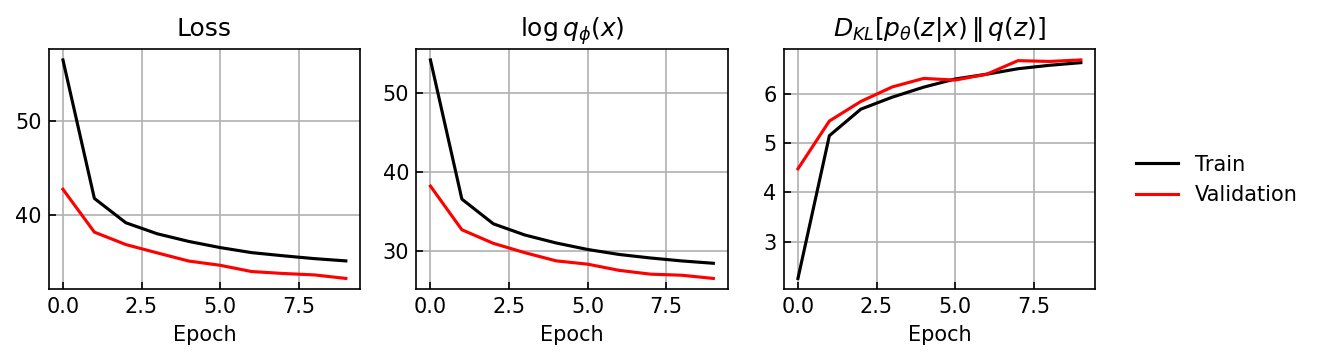

In [12]:
fig, ax = plt.subplots(1, 3, sharex=True, figsize=(7.5, 2.5))

for i, key in enumerate(['loss', 'recon', 'kld']):
    ax[i].plot(model_stats['train_'+key], color='black', label='Train')
    ax[i].plot(model_stats['val_'+key], color='red', label='Validation')
    ax[i].set(xlabel='Epoch')

ax[0].set_title('Loss')
ax[1].set_title(r'$\log q_{\phi}(x)$')
ax[2].set_title(r'$D_{KL} [ p_{\theta}(z | x) \, \Vert \, q(z) ]$')

fig.legend(*ax[0].get_legend_handles_labels(), 
           loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

### Inference

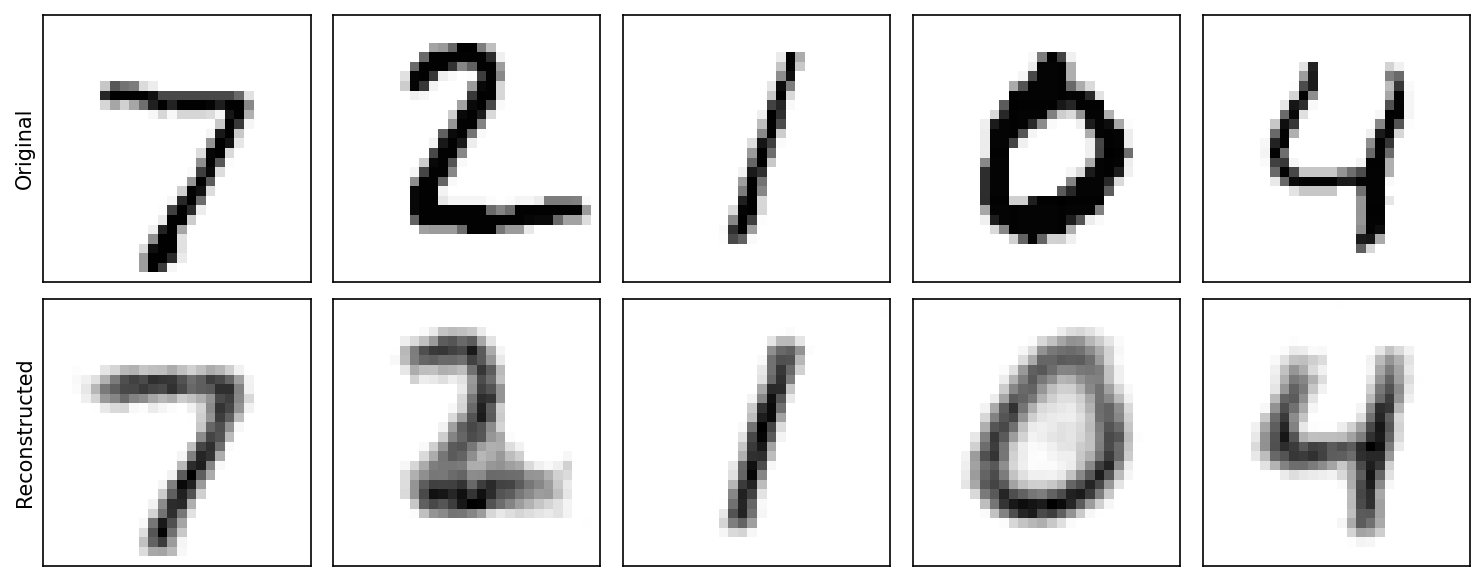

In [13]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4), sharex=True, sharey=True)
for ii in range(5):
    xb, _ = mnist_test[ii]
    ax[0, ii].imshow(xb.squeeze().cpu().numpy(), cmap='Greys')
    with torch.no_grad():
        x_pred, z_pred, params = model(xb.to(device))
    ax[1, ii].imshow(x_pred.squeeze().cpu().numpy(), cmap='Greys')

ax[0,0].set_ylabel('Original')
ax[1,0].set_ylabel('Reconstructed')

for a in ax.flatten():
    a.set(xticks=[], yticks=[])
plt.tight_layout()

In [14]:
# Inference
model.eval()
test_loader = DataLoader(mnist_test, batch_size=128, shuffle=False)

y_true = []
z_pred = []

with torch.no_grad():
    for xb, yb in tqdm(test_loader,leave=False):
        xb = xb.to(device)
        xp, zp, params = model(xb)
        y_true.append(yb.cpu().numpy())
        z_pred.append(zp.cpu().numpy())

y_true = np.concatenate(y_true)
z_pred = np.concatenate(z_pred)

  0%|          | 0/79 [00:00<?, ?it/s]

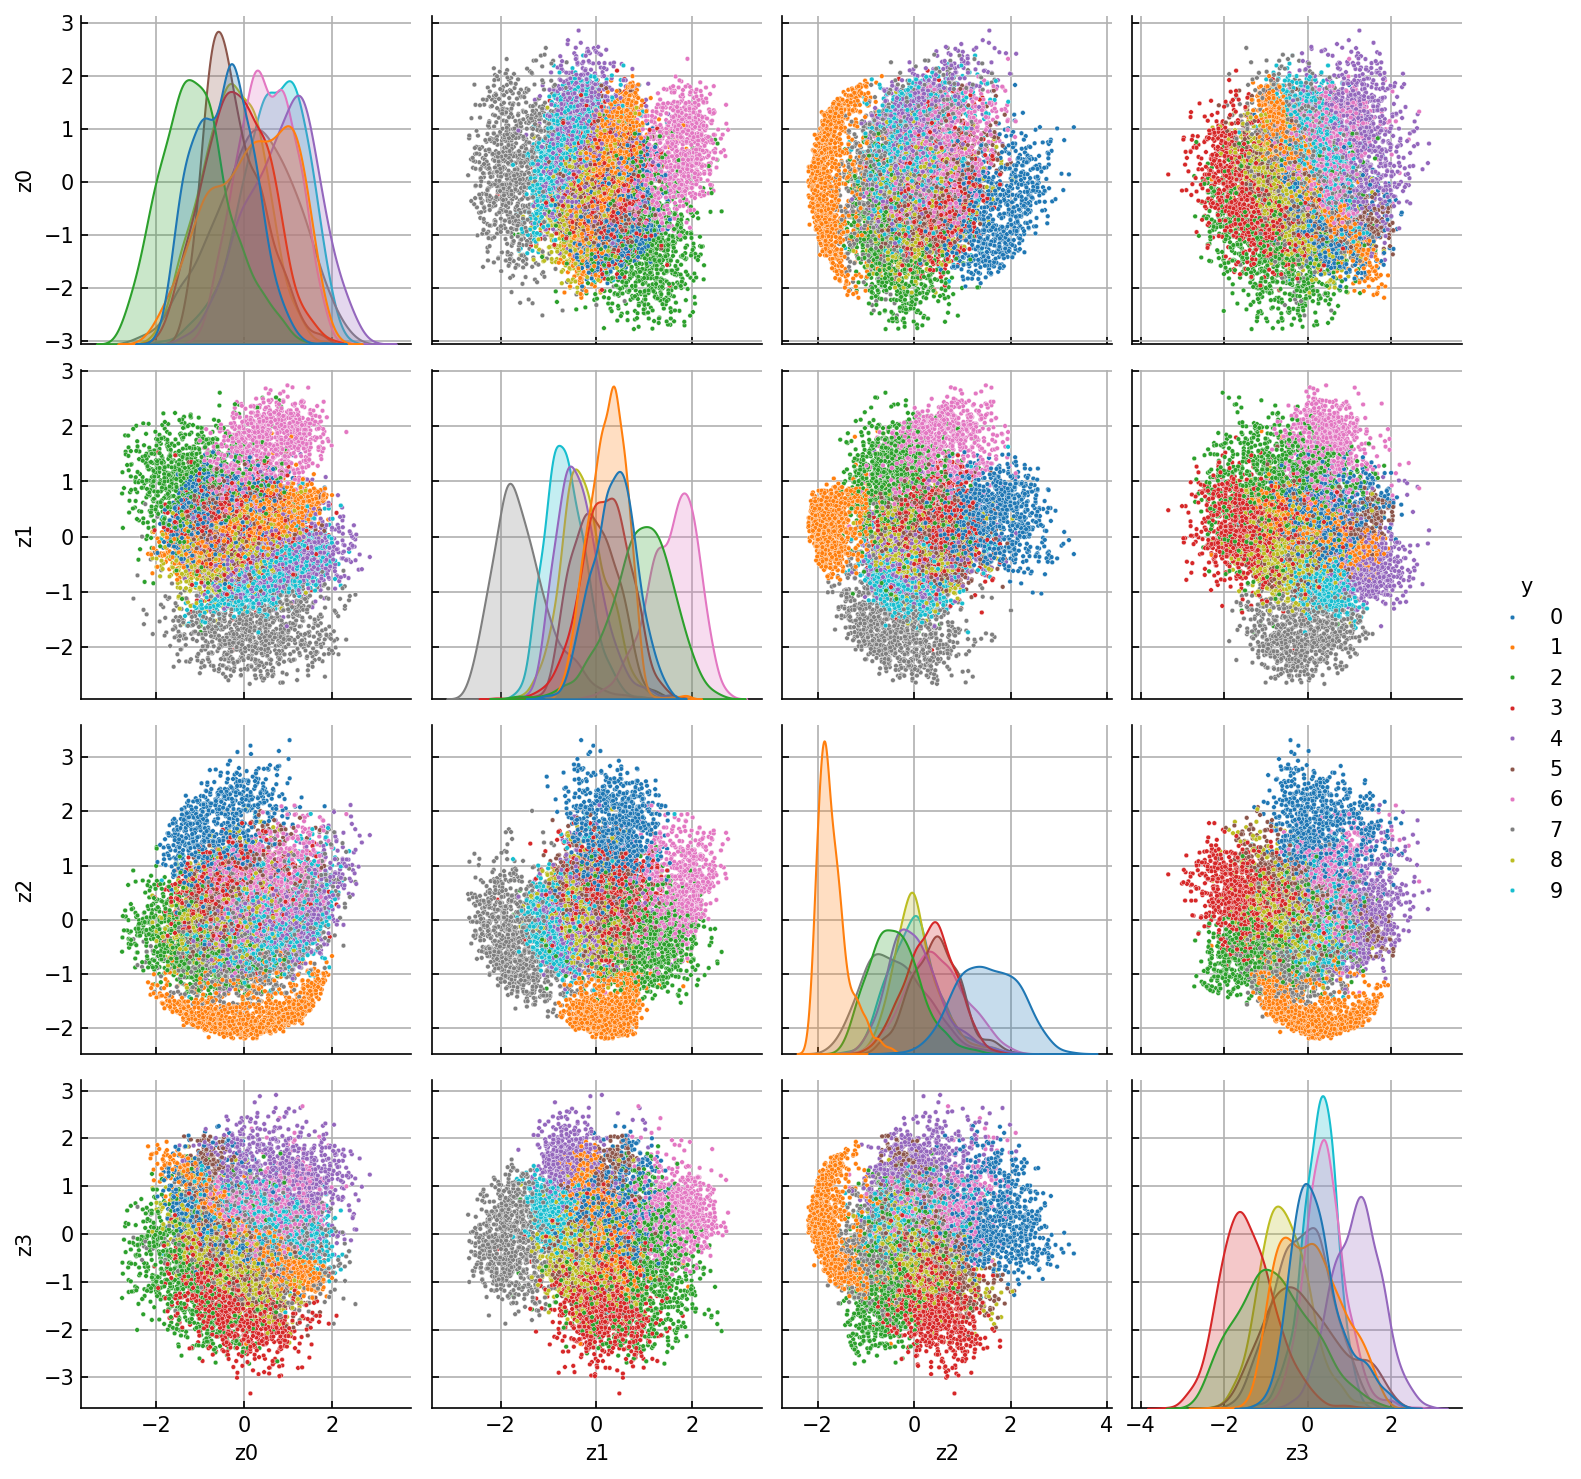

In [15]:
import seaborn as sns

df = pd.DataFrame({
    'z0': z_pred[:, 0],
    'z1': z_pred[:, 1],
    'z2': z_pred[:, 2],
    'z3': z_pred[:, 3],
    'y': y_true
})

sns.pairplot(df, hue='y', palette='tab10', plot_kws={'s': 5})

[Text(0.5, 0, 't-SNE 1'), Text(0, 0.5, 't-SNE 2')]

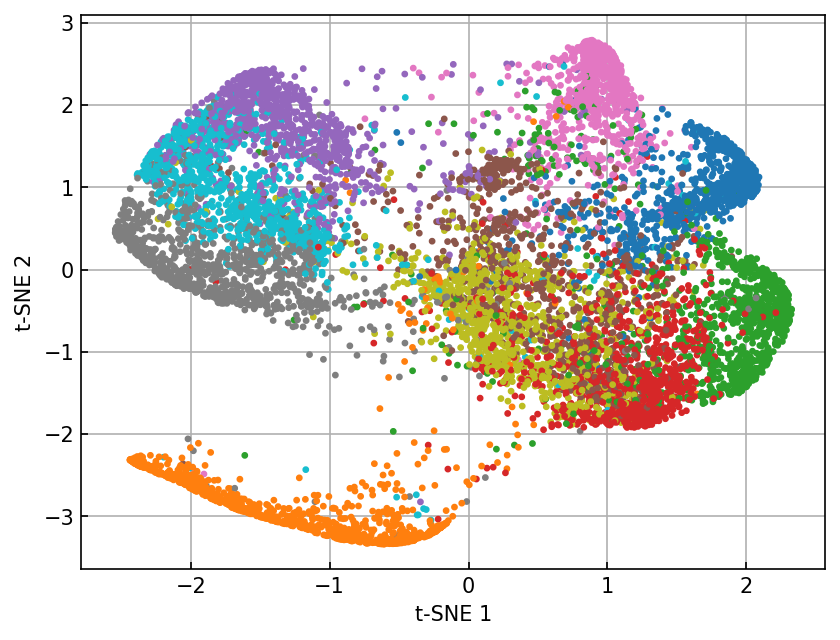

In [16]:
from sklearn.manifold import TSNE

viz = TSNE(n_components=2, n_iter=250)
z_2d = viz.fit_transform(z_pred)

fig, ax = plt.subplots()
ax.scatter(
    z_2d[:, 0],
    z_2d[:, 1],
    c=y_true,
    cmap='tab10',
    s=5
)
ax.set(xlabel='t-SNE 1', ylabel='t-SNE 2')

## $\beta$-VAE

In [19]:
class BetaVAELoss(nn.Module):
    def __init__(self, beta=1.):
        super().__init__()
        self.beta = beta
        
    def forward(self, x_pred, x_true, z_pred, mu, logvar):
        B = x_pred.shape[0]
        recon = F.mse_loss(x_pred, x_true, reduction='sum') / B
        kld = 0.5 * torch.sum( mu*mu + logvar.exp() - logvar - 1) / B
        loss = recon + self.beta * kld
        return loss, {
            'loss': loss.item(),
            'recon': recon.item(),
            'kld': kld.item()
        }

# Fix training recipe
train_kwargs = dict(train_dataset=mnist_train, val_dataset=mnist_val, num_epochs=10, batch_size=64, num_workers=4)

In [20]:
# Model with heavy regularization
model1 = VariationalAutoencoder()
opt1 = torch.optim.Adam(model1.parameters(), lr=1e-4)
loss1 = BetaVAELoss(beta=10.)

model1, model1_stats = train(model1, loss1, opt1, **train_kwargs)

  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 1 | train_loss 57.246 | train_recon 57.114 | train_kld 0.013 | val_loss 53.450 | val_recon 53.425 | val_kld 0.003 |


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 2 | train_loss 53.368 | train_recon 53.345 | train_kld 0.002 | val_loss 53.144 | val_recon 53.123 | val_kld 0.002 |


... (20 outputs left out)

Epoch 9 | train_loss 52.863 | train_recon 52.856 | train_kld 0.001 | val_loss 52.931 | val_recon 52.927 | val_kld 0.000 |


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 10 | train_loss 52.845 | train_recon 52.840 | train_kld 0.001 | val_loss 52.911 | val_recon 52.906 | val_kld 0.000 |


In [21]:
# Model with minimal regularization
model2 = VariationalAutoencoder()
opt2 = torch.optim.Adam(model2.parameters(), lr=1e-4)
loss2 = BetaVAELoss(beta=1e-2)

model2, model2_stats = train(model2, loss2, opt2, **train_kwargs)

  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 1 | train_loss 45.319 | train_recon 45.183 | train_kld 13.577 | val_loss 36.200 | val_recon 36.018 | val_kld 18.229 |


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 2 | train_loss 33.979 | train_recon 33.797 | train_kld 18.192 | val_loss 32.246 | val_recon 32.065 | val_kld 18.128 |


... (20 outputs left out)

Epoch 9 | train_loss 26.721 | train_recon 26.541 | train_kld 18.031 | val_loss 26.773 | val_recon 26.595 | val_kld 17.803 |


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 10 | train_loss 26.461 | train_recon 26.281 | train_kld 17.970 | val_loss 26.538 | val_recon 26.355 | val_kld 18.305 |


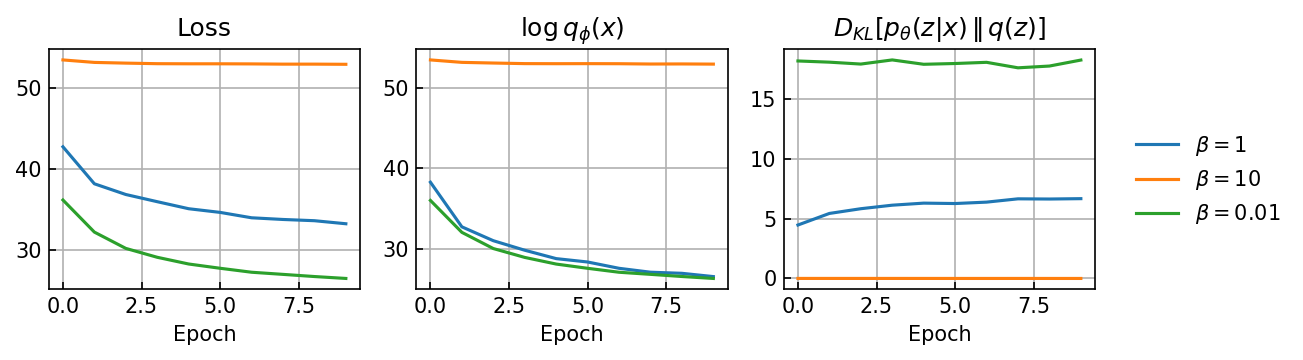

In [22]:
fig, ax = plt.subplots(1, 3, sharex=True, figsize=(7.5, 2.5))

for i, key in enumerate(['loss', 'recon', 'kld']):
    ax[i].plot(model_stats['val_'+key], label='$\\beta = 1$')
    ax[i].plot(model1_stats['val_'+key], label='$\\beta = 10$')
    ax[i].plot(model2_stats['val_'+key], label='$\\beta = 0.01$')
    ax[i].set(xlabel='Epoch')

ax[0].set_title('Loss')
ax[1].set_title(r'$\log q_{\phi}(x)$')
ax[2].set_title(r'$D_{KL} [ p_{\theta}(z | x) \, \Vert \, q(z) ]$')

fig.legend(*ax[0].get_legend_handles_labels(), 
           loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

### Inference

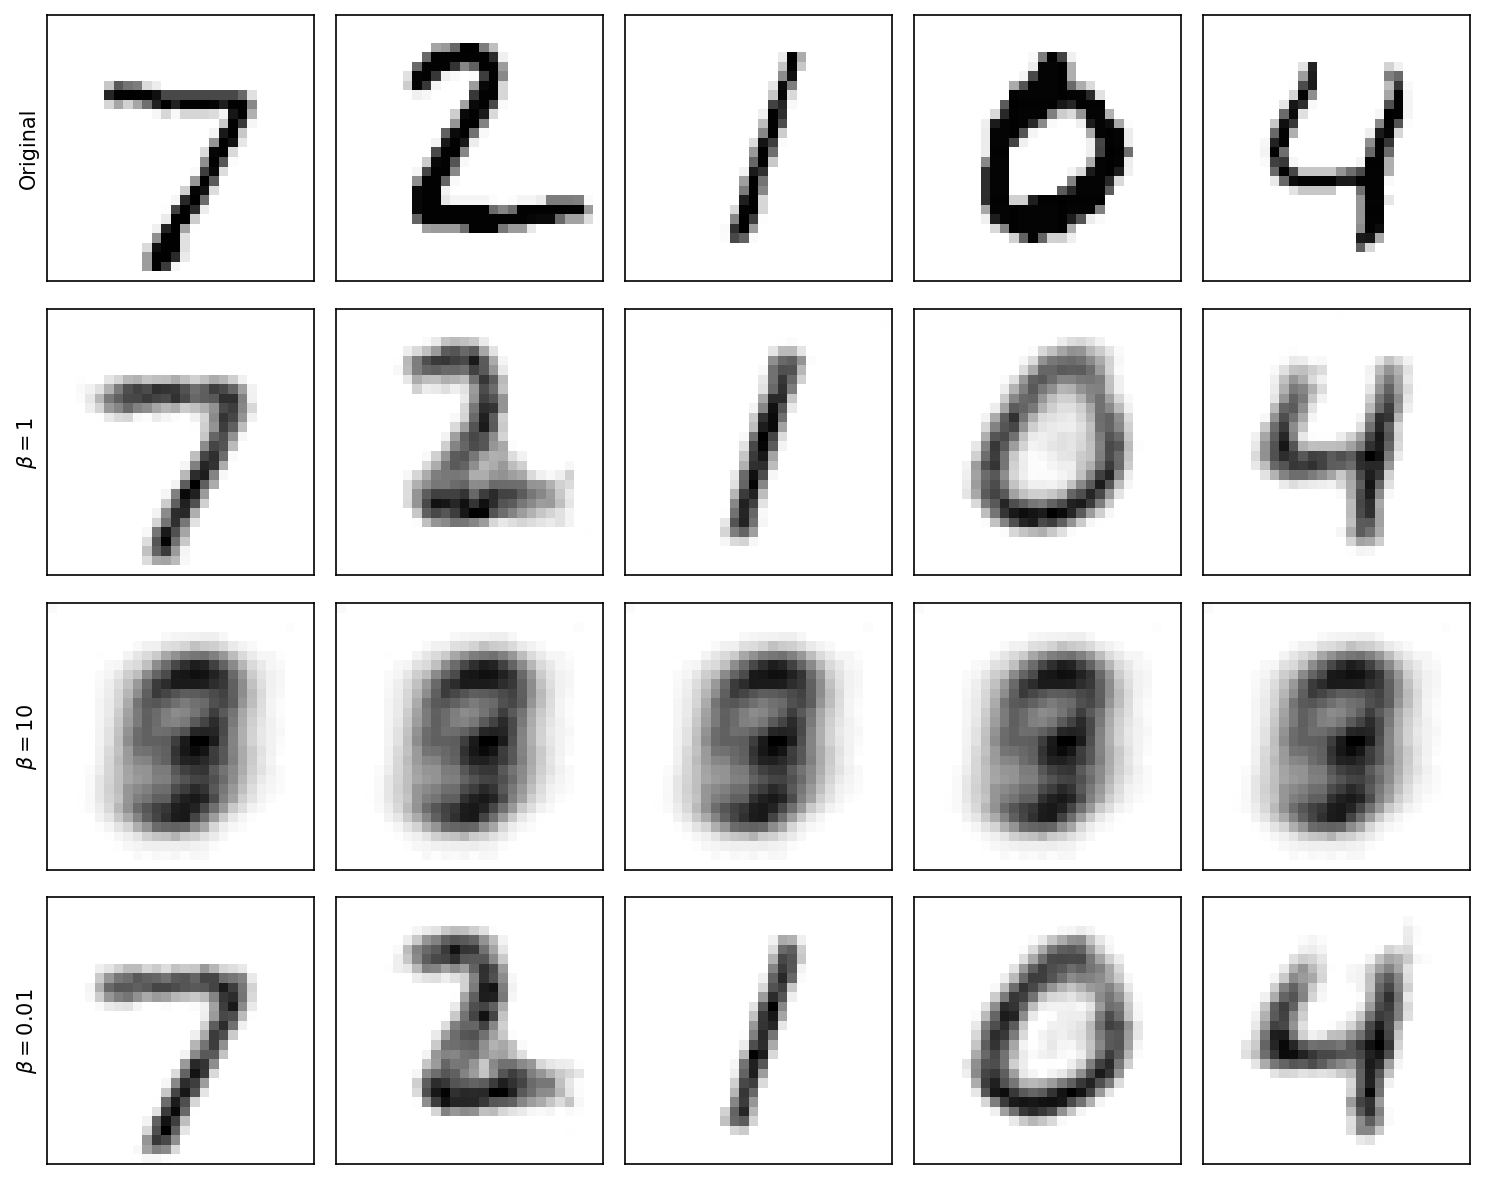

In [23]:
fig, ax = plt.subplots(4, 5, figsize=(10, 8), sharex=True, sharey=True)
for ii in range(5):
    xb, _ = mnist_test[ii]
    ax[0, ii].imshow(xb.squeeze().cpu().numpy(), cmap='Greys')
    with torch.no_grad():
        x_pred, z_pred, params = model(xb.to(device))
        ax[1, ii].imshow(x_pred.squeeze().cpu().numpy(), cmap='Greys')

        x_pred, z_pred, params = model1(xb.to(device))
        ax[2, ii].imshow(x_pred.squeeze().cpu().numpy(), cmap='Greys')

        x_pred, z_pred, params = model2(xb.to(device))
        ax[3, ii].imshow(x_pred.squeeze().cpu().numpy(), cmap='Greys')

ax[0,0].set_ylabel('Original')
ax[1,0].set_ylabel('$\\beta = 1$')
ax[2,0].set_ylabel('$\\beta = 10$')
ax[3,0].set_ylabel('$\\beta = 0.01$')

for a in ax.flatten():
    a.set(xticks=[], yticks=[])
plt.tight_layout()

In [24]:
# Inference
model.eval()
test_loader = DataLoader(mnist_test, batch_size=128, shuffle=False)

y_true = []
z0_pred = []
z1_pred = []
z2_pred = []
with torch.no_grad():
    for xb, yb in tqdm(test_loader,leave=False):
        xb = xb.to(device)
        y_true.append(yb.cpu().numpy())

        xp, zp, params = model(xb)
        z0_pred.append(zp.cpu().numpy())

        xp, zp, params = model1(xb)
        z1_pred.append(zp.cpu().numpy())

        xp, zp, params = model2(xb)
        z2_pred.append(zp.cpu().numpy())

y_true = np.concatenate(y_true)
z0_pred = np.concatenate(z0_pred)
z1_pred = np.concatenate(z1_pred)
z2_pred = np.concatenate(z2_pred)

  0%|          | 0/79 [00:00<?, ?it/s]

In [25]:
from sklearn.manifold import TSNE

viz = TSNE(n_components=2, n_iter=250)
z0_2d = viz.fit_transform(z0_pred)
z1_2d = viz.fit_transform(z1_pred)
z2_2d = viz.fit_transform(z2_pred)

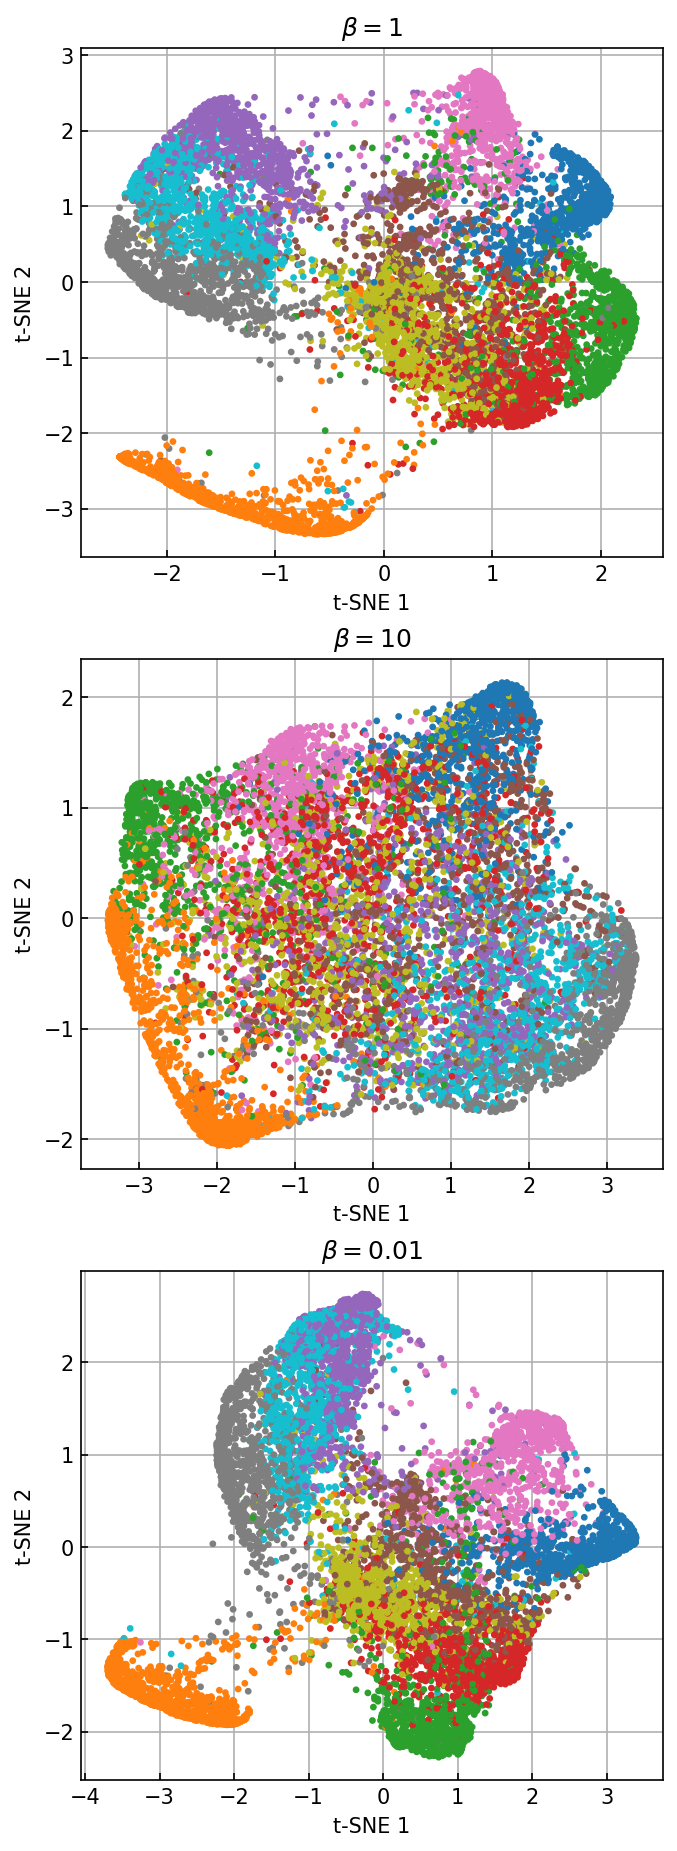

In [26]:
from sklearn.manifold import TSNE

fig, axes = plt.subplots(3, 1, figsize=(5, 15))

for ax, z_2d in zip(axes, [z0_2d, z1_2d, z2_2d]):
    ax.scatter(
        z_2d[:, 0],
        z_2d[:, 1],
        c=y_true,
        cmap='tab10',
        s=5
    )
    ax.set(xlabel='t-SNE 1', ylabel='t-SNE 2')

axes[0].set_title('$\\beta = 1$')
axes[1].set_title('$\\beta = 10$')
axes[2].set_title('$\\beta = 0.01$');

## Latent traversal

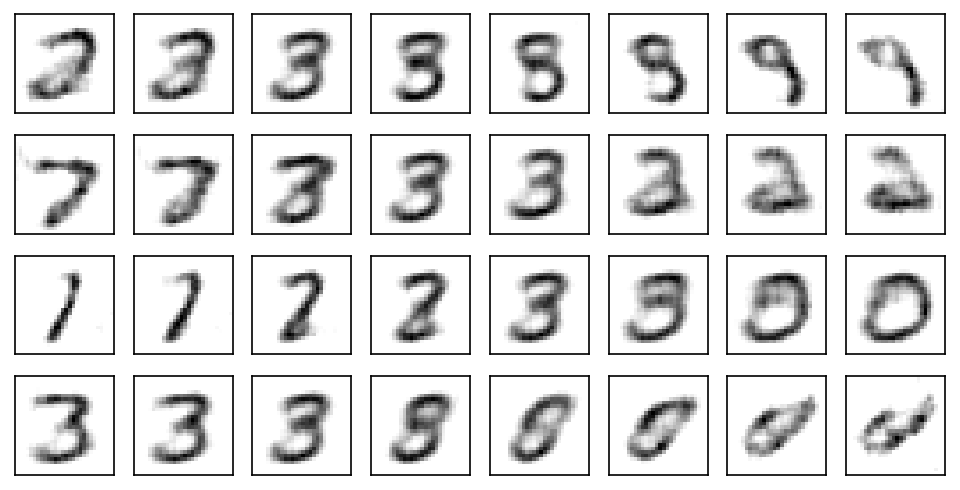

In [27]:
fig, ax = plt.subplots(4, 8, figsize=(8, 4), sharex=True, sharey=True)

with torch.no_grad():
    z_base = torch.randn(1, 4, device=device, dtype=torch.float) # Starting latent vector
    z_trav = torch.linspace(-3, 3, 8, device=device, dtype=torch.float) # Traversal values

    for ii in range(4):
        z = z_base.repeat(8, 1)
        z[:, ii] = z_trav
        x_pred = model.decoder(z).cpu().numpy()
        for jj in range(8):
            ax[ii, jj].imshow(x_pred[jj,0], cmap='Greys')
            ax[ii, jj].set(xticks=[], yticks=[])